In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)


All libraries imported successfully!
TensorFlow version: 2.21.0


In [2]:

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())


Saving archive (2).zip to archive (2).zip
Dataset loaded successfully!
Dataset shape: (22000, 2)

Column names:
['Text', 'language']

First 5 rows:


,Text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch


In [4]:

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Find text and language columns
column_map = {c.lower(): c for c in df.columns}

text_candidates = ["text", "text_sample", "sentence", "text_snippet"]
label_candidates = ["language", "lang", "label"]

text_col = next(
    (column_map[c] for c in text_candidates if c in column_map),
    None
)

label_col = next(
    (column_map[c] for c in label_candidates if c in column_map),
    None
)

print("Text column:", text_col)
print("Language column:", label_col)

if text_col is None or label_col is None:
    raise ValueError(
        "Text/language columns not identified. "
        "Check the column names printed in Step 4."
    )

# Keep only required columns
df = df[[text_col, label_col]].copy()

# Handle missing values
df = df.dropna(subset=[text_col, label_col])

# Preprocess text
df[text_col] = df[text_col].astype(str).str.strip()
df[label_col] = df[label_col].astype(str).str.strip()

# Remove empty values and duplicates
df = df[
    (df[text_col] != "") &
    (df[label_col] != "")
]

df = df.drop_duplicates(subset=[text_col, label_col])

print("\nCleaned dataset shape:", df.shape)
print("\nSamples per language:")
print(df[label_col].value_counts())


Text column: Text
Language column: language

Cleaned dataset shape: (21858, 2)

Samples per language:
language
Japanese      1000
Thai          1000
Korean        1000
Chinese       1000
Urdu          1000
Turkish       1000
Romanian      1000
English       1000
Persian       1000
Estonian       999
Russian        999
Arabic         998
Portugese      997
Spanish        996
Dutch          995
Pushto         993
Swedish        992
French         990
Hindi          990
Tamil          981
Indonesian     975
Latin          953
Name: count, dtype: int64


In [5]:

# Select maximum 500 samples per language
df = (
    df.groupby(label_col, group_keys=False)
      .sample(n=500, random_state=42)
      if df[label_col].value_counts().min() >= 500
      else df.groupby(label_col, group_keys=False)
             .apply(lambda x: x.sample(
                 n=min(500, len(x)),
                 random_state=42
             ))
             .reset_index(drop=True)
)

print("Subset shape:", df.shape)
print("Number of languages:", df[label_col].nunique())
print("\nLanguage distribution:")
print(df[label_col].value_counts())


Subset shape: (11000, 2)
Number of languages: 22

Language distribution:
language
Arabic        500
Chinese       500
Dutch         500
English       500
Estonian      500
French        500
Hindi         500
Indonesian    500
Japanese      500
Korean        500
Latin         500
Persian       500
Portugese     500
Pushto        500
Romanian      500
Russian       500
Spanish       500
Swedish       500
Tamil         500
Thai          500
Turkish       500
Urdu          500
Name: count, dtype: int64


In [6]:

X = df[text_col].tolist()
y = df[label_col].tolist()

# Convert language names into numeric labels
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

num_classes = len(encoder.classes_)

print("Total languages:", num_classes)
print("Language names:", list(encoder.classes_))


Total languages: 22
Language names: [np.str_('Arabic'), np.str_('Chinese'), np.str_('Dutch'), np.str_('English'), np.str_('Estonian'), np.str_('French'), np.str_('Hindi'), np.str_('Indonesian'), np.str_('Japanese'), np.str_('Korean'), np.str_('Latin'), np.str_('Persian'), np.str_('Portugese'), np.str_('Pushto'), np.str_('Romanian'), np.str_('Russian'), np.str_('Spanish'), np.str_('Swedish'), np.str_('Tamil'), np.str_('Thai'), np.str_('Turkish'), np.str_('Urdu')]


In [7]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 8800
Testing samples: 2200


In [13]:

# Step 9: Tokenization and Padding

vocab_size = 20000
max_length = 150

tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token="<OOV>",
    filters=""
)

tokenizer.fit_on_texts(X_train)

train_sequences = tokenizer.texts_to_sequences(X_train)
test_sequences = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    train_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    test_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)
print("Tokenization and padding completed!")


Training shape: (8800, 150)
Testing shape: (2200, 150)
Tokenization and padding completed!


In [29]:
for lang in sorted(df[label_col].unique()):
    print(f"\nLanguage: {lang}")
    print(df[df[label_col] == lang][text_col].head(3).tolist())


Language: Arabic
['ولكن سيمور قامت بسحب قصتها لاحقا وتقدم رجل اخر مدعيا بأنه يعلم هوية القاتل الحقيقي ظهور هذا الدليل الجديد وتصرفات القاضي في كل من القضية المبدأية والاستئنافية  دعى أعضاء البرلمان من الأحزاب السياسية الثلاثة الرئيسة إلى استجواب وزير الداخلية في هذا الشأن وعلى الرغم من وجود العديد من دعوات الاستعطاف الا انه تم رفض جميع الاستئنافات وإعدام ويليمز في علم  كانت هذه القضية احد أولى القضايا في المملكة المتحدة التي استخدمت علم القذائف', 'استمرت هذه الابادة حتى أنهاها القائمون على خدمة التنزه الوطني عام  مع صدور قانون حماية الأنواع المهددة بالانقراض عام عدّ الذئب واحداً من أنواع الثديات المذكورة بعد أن تم اجتثاث الذئاب من ويلستون صنّف الذئب في أعلى قائمة الكلاب المفترسة ومع ذلك فإن الذئاب ليست قادرة على افتراس الحيوانات الكبيرة ونتج عن النقص الحاد في عدد الكلاب المفترسة زيادة ملحوظة في عدد الحيوانات المريضة والضخمة', 'حمض البورونيك هو حمض مشتق من حمض البوريك وذلك بوجود مستبدل عضوي مثل ألكيل أو أريل ضمن البنية بالتالي وجود رابطة بين البورون والكربون لذلك فإن المركب هو من مركبا

In [30]:

# STEP 1: Required libraries
import numpy as np
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# STEP 2: Prepare text and labels
X = df[text_col].astype(str).tolist()
y = df[label_col].astype(str).tolist()

encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)
num_classes = len(encoder.classes_)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

# STEP 3: Character-level tokenization
tokenizer = Tokenizer(
    char_level=True,
    lower=False,
    filters="",
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

vocab_size = len(tokenizer.word_index) + 1
max_length = 200

X_train_pad = pad_sequences(
    tokenizer.texts_to_sequences(X_train),
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    tokenizer.texts_to_sequences(X_test),
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("Vocabulary size:", vocab_size)
print("Number of languages:", num_classes)

# STEP 4: Build Character-level BiLSTM
model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),
    Bidirectional(LSTM(64)),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# STEP 5: Train the model
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=8,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

# STEP 6: Evaluate on test data
test_loss, test_accuracy = model.evaluate(
    X_test_pad, y_test, verbose=0
)

print(f"\nTest Accuracy: {test_accuracy * 100:.2f}%")

y_pred = np.argmax(model.predict(X_test_pad, verbose=0), axis=1)

print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(num_classes),
    target_names=encoder.classes_,
    zero_division=0
))


Vocabulary size: 5868
Number of languages: 22


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
124/124 ━━━━━━━━━━━━━━━━━━━━ 62s 438ms/step - accuracy: 0.2583 - loss: 2.2539 - val_accuracy: 0.3523 - val_loss: 1.6072
Epoch 2/8
124/124 ━━━━━━━━━━━━━━━━━━━━ 85s 469ms/step - accuracy: 0.4140 - loss: 1.6008 - val_accuracy: 0.4034 - val_loss: 1.4760
Epoch 3/8
124/124 ━━━━━━━━━━━━━━━━━━━━ 79s 444ms/step - accuracy: 0.5085 - loss: 1.3058 - val_accuracy: 0.5693 - val_loss: 1.1157
Epoch 4/8
124/124 ━━━━━━━━━━━━━━━━━━━━ 83s 456ms/step - accuracy: 0.5121 - loss: 1.4093 - val_accuracy: 0.5784 - val_loss: 1.1630
Epoch 5/8
124/124 ━━━━━━━━━━━━━━━━━━━━ 55s 444ms/step - accuracy: 0.5665 - loss: 1.1829 - val_accuracy: 0.5773 - val_loss: 1.0751
Epoch 6/8
124/124 ━━━━━━━━━━━━━━━━━━━━ 53s 426ms/step - accuracy: 0.5943 - loss: 1.0925 - val_accuracy: 0.5955 - val_loss: 1.0783
Epoch 7/8
124/124 ━━━━━━━━━━━━━━━━━━━━ 53s 432ms/step - accuracy: 0.6359 - loss: 0.9749 - val_accuracy: 0.6011 - val_loss: 1.0872

Test Accuracy: 59.77%
              precision    recall  f1-score   support

      Arabic

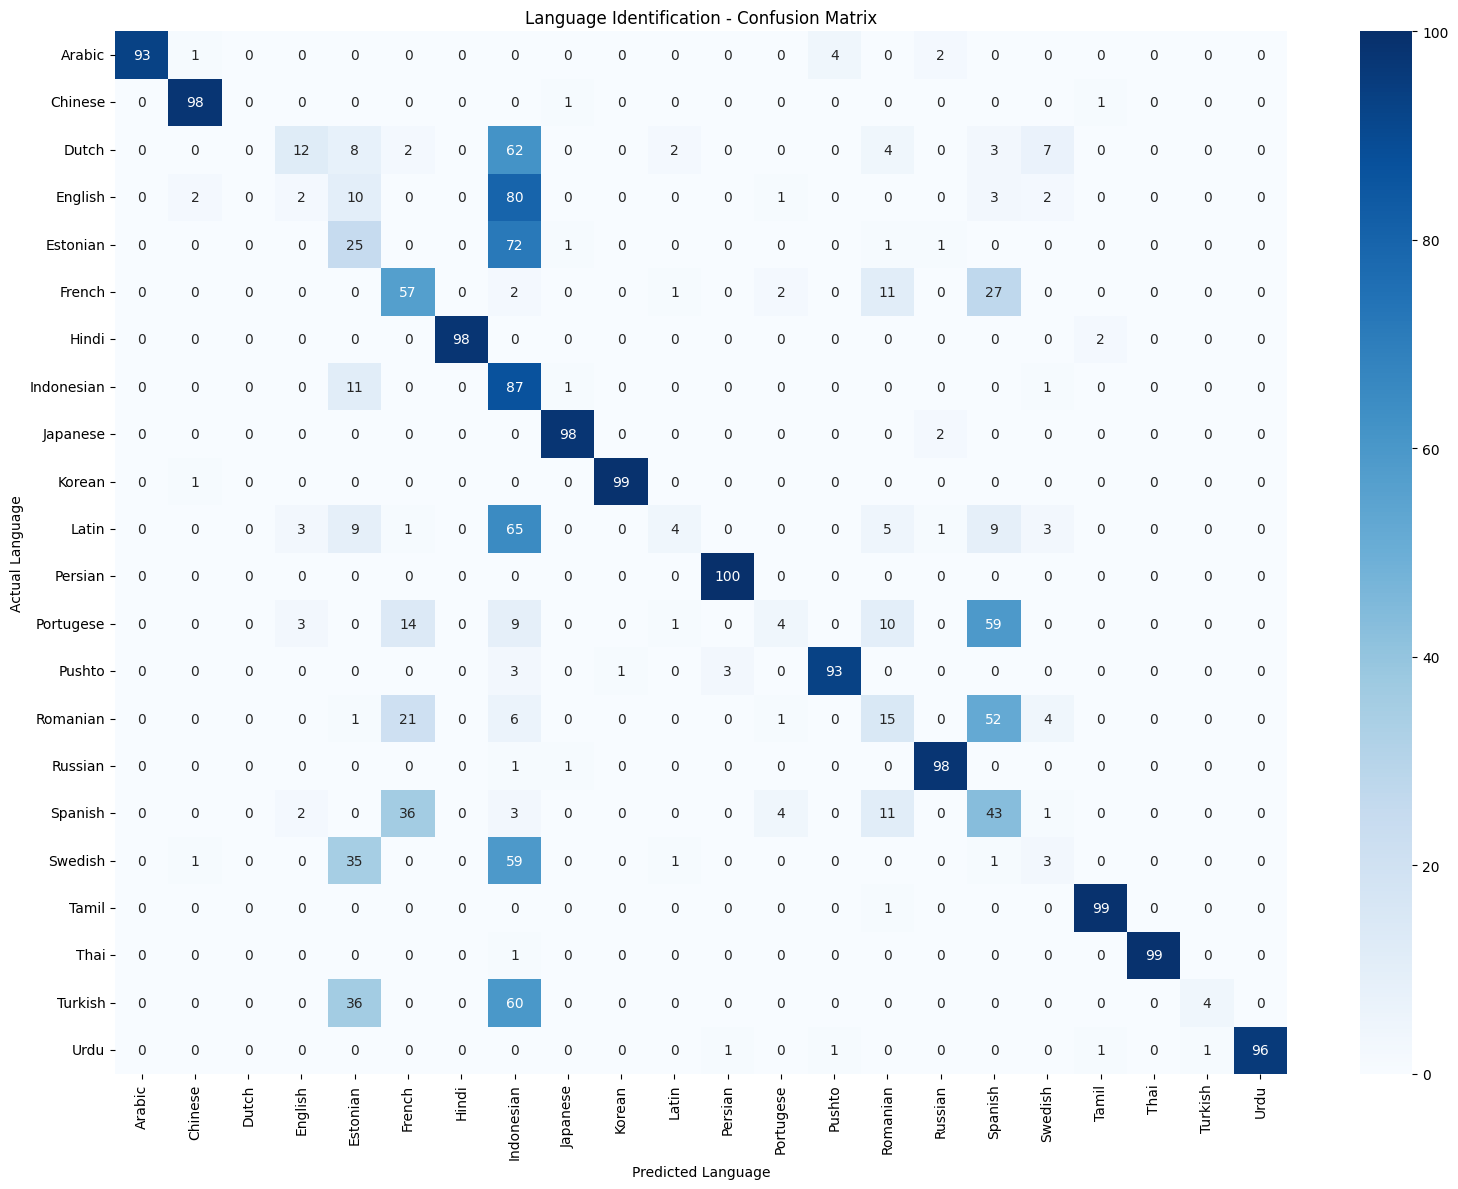

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

y_pred = np.argmax(model.predict(X_test_pad, verbose=0), axis=1)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(16, 12))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.xlabel("Predicted Language")
plt.ylabel("Actual Language")
plt.title("Language Identification - Confusion Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [32]:
wrong_indices = np.where(y_test != y_pred)[0]

for i in wrong_indices[:20]:
    actual = encoder.inverse_transform([y_test[i]])[0]
    predicted = encoder.inverse_transform([y_pred[i]])[0]

    print("Text:", X_test[i][:200])
    print("Actual:", actual)
    print("Predicted:", predicted)
    print("-" * 50)

Text: yılında üsküpte doğan numan pura sanat çalışmalarına kendi çabasıyla başladı i̇lk kişisel sergisini  yılında balıkesirde açtı hayatı boyunca yurtiçi ve yurtdışında toplam  kişisel sergi açtı ve çok sa
Actual: Turkish
Predicted: Indonesian
--------------------------------------------------
Text: "los dramas de la conciencia y la memoria" en la memoria literaria del franquismo anales de literatura española   serie monográfica núm  pp -
Actual: Spanish
Predicted: French
--------------------------------------------------
Text: dublin on riikliku transpordi keskpunkt dublini sadam on riigi kõige elavam meresadam ja dublini lennujaam samamoodi riigi kõige kasutatavam lennuväli
Actual: Estonian
Predicted: Indonesian
--------------------------------------------------
Text: mai partidul conservator din regatul unit condus de david cameron a obținut majoritatea absolută în urma alegerilor legislative pentru camera comunelor
Actual: Romanian
Predicted: Swedish
------------------------------

In [33]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_more = model.fit(
    X_train_pad,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/15
124/124 ━━━━━━━━━━━━━━━━━━━━ 63s 504ms/step - accuracy: 0.5951 - loss: 1.0752 - val_accuracy: 0.6500 - val_loss: 1.0054
Epoch 2/15
124/124 ━━━━━━━━━━━━━━━━━━━━ 79s 482ms/step - accuracy: 0.6063 - loss: 1.0719 - val_accuracy: 0.6670 - val_loss: 0.9425
Epoch 3/15
124/124 ━━━━━━━━━━━━━━━━━━━━ 56s 447ms/step - accuracy: 0.6352 - loss: 0.9779 - val_accuracy: 0.6761 - val_loss: 0.9571
Epoch 4/15
124/124 ━━━━━━━━━━━━━━━━━━━━ 62s 498ms/step - accuracy: 0.6769 - loss: 0.8817 - val_accuracy: 0.7375 - val_loss: 0.7556
Epoch 5/15
124/124 ━━━━━━━━━━━━━━━━━━━━ 80s 482ms/step - accuracy: 0.6924 - loss: 0.8672 - val_accuracy: 0.7193 - val_loss: 0.7259
Epoch 6/15
124/124 ━━━━━━━━━━━━━━━━━━━━ 77s 440ms/step - accuracy: 0.6725 - loss: 0.9280 - val_accuracy: 0.7545 - val_loss: 0.7300
Epoch 7/15
124/124 ━━━━━━━━━━━━━━━━━━━━ 55s 441ms/step - accuracy: 0.7468 - loss: 0.7179 - val_accuracy: 0.5625 - val_loss: 1.7212
Epoch 8/15
124/124 ━━━━━━━━━━━━━━━━━━━━ 56s 453ms/step - accuracy: 0.6856 - loss: 0

In [34]:
loss, accuracy = model.evaluate(X_test_pad, y_test, verbose=0)
print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Accuracy: 90.32%


In [35]:

from sklearn.metrics import classification_report, accuracy_score
import numpy as np

y_pred = np.argmax(model.predict(X_test_pad, verbose=0), axis=1)

print("Final Test Accuracy:",
      f"{accuracy_score(y_test, y_pred) * 100:.2f}%")

print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(num_classes),
    target_names=encoder.classes_,
    zero_division=0
))


Final Test Accuracy: 90.32%

Classification Report:

              precision    recall  f1-score   support

      Arabic       1.00      0.99      0.99       100
     Chinese       0.97      1.00      0.99       100
       Dutch       0.77      0.65      0.71       100
     English       0.64      0.83      0.72       100
    Estonian       0.97      0.85      0.90       100
      French       0.97      0.94      0.95       100
       Hindi       1.00      0.99      0.99       100
  Indonesian       0.91      0.95      0.93       100
    Japanese       1.00      0.99      0.99       100
      Korean       1.00      0.99      0.99       100
       Latin       0.85      0.80      0.82       100
     Persian       0.98      0.94      0.96       100
   Portugese       0.61      0.55      0.58       100
      Pushto       0.94      0.96      0.95       100
    Romanian       0.97      0.94      0.95       100
     Russian       0.98      0.97      0.97       100
     Spanish       0.52     

In [36]:

def predict_language(text):
    sequence = tokenizer.texts_to_sequences([text])

    padded = pad_sequences(
        sequence,
        maxlen=max_length,
        padding="post",
        truncating="post"
    )

    probabilities = model.predict(padded, verbose=0)[0]
    index = np.argmax(probabilities)

    language = encoder.inverse_transform([index])[0]
    confidence = probabilities[index] * 100

    print("Input Text:", text)
    print("Predicted Language:", language)
    print(f"Confidence: {confidence:.2f}%")

predict_language("வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?")
predict_language("Hello, how are you today?")
predict_language("Bonjour, comment allez-vous ?")
predict_language("नमस्ते, आप कैसे हैं?")


Input Text: வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?
Predicted Language: Tamil
Confidence: 99.99%
Input Text: Hello, how are you today?
Predicted Language: English
Confidence: 32.21%
Input Text: Bonjour, comment allez-vous ?
Predicted Language: Romanian
Confidence: 43.08%
Input Text: नमस्ते, आप कैसे हैं?
Predicted Language: Hindi
Confidence: 99.98%


In [37]:

model.save("language_lstm.keras")

print("Model saved successfully!")


Model saved successfully!


In [38]:

from google.colab import files

files.download("language_lstm.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

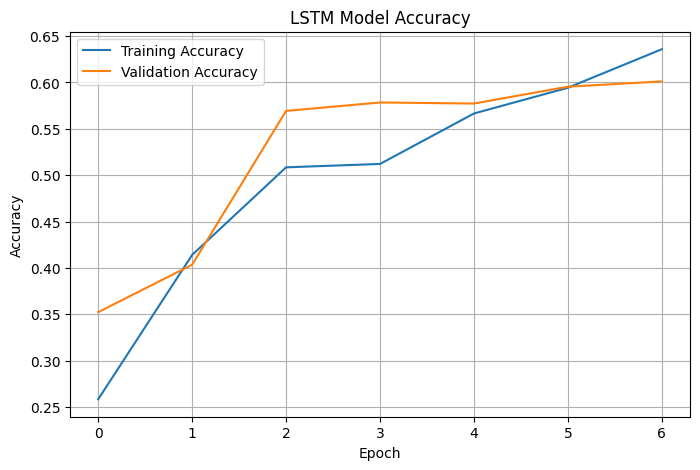

In [39]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Model Accuracy")
plt.legend()
plt.grid(True)
plt.show()
